# Practical Session 10 &mdash; B. How many groups, and clouds

k-means needs $K$, the number of groups, before it starts. This notebook first asks how to choose $K$, with the
two usual hints, and what those hints say when there are no groups at all. Then it lets every group become a
**cloud**: a group that can stretch, tilt and be bigger or smaller than the others, and that can **share** a
point with another group.

| | Notebook | What you do |
|---|---|---|
| A | k-means, and what can go wrong | k-means by hand, a photo, bad starts, scoring by counting pairs, units |
| **B** | **How many groups, and clouds** | **the elbow and the silhouette; Gaussian mixtures and soft memberships (this notebook)** |
| C | Crowds, trees, and choosing | DBSCAN and hierarchical clustering by hand; which method for which situation |

> &#11088; **Key idea.** $K$ is **your decision**: the elbow and the silhouette are hints, and they answer even
> when there are no groups. A cloud adds a **shape** and a **how sure** to every group.

The data: the rents of eight apartments, 178 wines (real data), 500 random points, three overlapping blobs,
three made-up clouds, tilted clouds, a small group beside a big one, and 150 iris flowers (real data). As
before, the true groups are used only to *score* a grouping, never to find it.

*Run the cells in order (Shift+Enter). Self-contained and offline; the whole notebook runs in about
30 seconds.*

In [1]:
import itertools
import warnings

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris, load_wine, make_blobs
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

from nb_utils import use_style
from nb_data import make_ellipses3, make_random_points, make_rent8, make_shapes, make_three_blobs

use_style("notes")
C0, C1, CG, CN = "#0072B2", "#D55E00", "#009E73", "#E69F00"
CP = "#CC79A7"                   # pink, when a fifth color is needed
CX = "0.62"                      # gray, for reference lines
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=[C0, C1, CG, CN, CP])   # frozen palette
COLORS = [C0, C1, CG, CN, CP]
RGB = np.array([mpl.colors.to_rgb(c) for c in COLORS])


def best_renaming(truth, found, relabel=False):
    '''how many points land in their true group, under the best renaming of the found groups
    (with relabel=True: the found groups renamed that way, so their colors match the truth)'''
    names, targets = np.unique(found), np.unique(truth).tolist()
    targets += [max(targets) + 1 + i for i in range(len(names) - len(targets))]   # spare names: more found groups than true ones
    perm = max(itertools.permutations(targets, len(names)),
               key=lambda p: sum(np.sum((found == a) & (truth == b)) for a, b in zip(names, p)))
    if relabel:
        return np.select([found == a for a in names], perm)
    return sum(np.sum((found == a) & (truth == b)) for a, b in zip(names, perm))


def draw_cloud(ax, mean, cov, color, sds=(1, 2)):
    "a cloud's outline: the ellipses 1 and 2 spreads (standard deviations) from its center"
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    for k in sds:
        ax.add_patch(Ellipse(mean, 2 * k * np.sqrt(vals[1]), 2 * k * np.sqrt(vals[0]), angle=angle,
                             facecolor="none", edgecolor=color, lw=1.8 if k == 1 else 1.1,
                             ls="-" if k == 1 else "--", zorder=4))


print("ready")

ready


## 1. How many groups? The elbow

The eight rents again: 2, 3, 4, 5, 10, 11, 12, 13. The cell runs k-means for every $K$ from 1 to 8 (with 50
starts each: with few starts, some $K$ get stuck) and prints the best cost for each.

**Predict first:** why not try $K = 1, 2, \dots, 8$ and keep the $K$ with the smallest cost?

best cost for K = 1..8: 138, 10, 6, 2, 1.5, 1, 0.5, 0
what one more group buys (the drop): 128, 4, 4, 0.5, 0.5, 0.5, 0.5


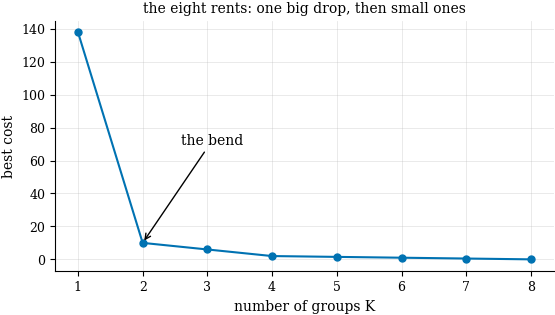

In [2]:
_, rents = make_rent8()
R = rents[:, None]                                     # scikit-learn wants one row per point
Ks = range(1, 9)
fits = {K: KMeans(n_clusters=K, n_init=50, random_state=0).fit(R) for K in Ks}
cost = {K: fits[K].inertia_ for K in Ks}
print("best cost for K = 1..8:", ", ".join(f"{cost[K]:g}" for K in Ks))
print("what one more group buys (the drop):", ", ".join(f"{cost[K] - cost[K + 1]:g}" for K in Ks if K < 8))

fig, ax = plt.subplots(figsize=(5.6, 3.2))
ax.plot(list(Ks), [cost[K] for K in Ks], "o-", color=C0)
ax.annotate("the bend", (2, cost[2]), (2.6, 70), arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_xlabel("number of groups K"); ax.set_ylabel("best cost")
ax.set_title("the eight rents: one big drop, then small ones", fontsize=10)
plt.show()

The best cost for $K = 1, 2, 3, 4$ is 138, 10, 6, 2, and it keeps falling: with $K = 8$ every rent is alone and
the cost is 0. **More groups always lower the cost**, so "the smallest cost" always picks the largest $K$ you
try. Look instead for the **elbow**: where one more group stops paying off. Here $K = 2$: a drop of 128, then
only 4 and 4.

A T-shirt shop decides between S/M/L and XS to XXL; customers do not come in sizes. $K$ is a **decision**; the
elbow and the silhouette (next) are hints.

## 2. The silhouette, by hand

For one point: $a$ = its average distance to the **other** points of its group; $b$ = its average distance to
the points of the nearest other group. Its **silhouette** is $s = (b - a)$ divided by the larger of $a$ and
$b$: near 1, comfortable in its group; near 0, on the fence; negative, probably in the wrong group. The
average over all points scores the grouping.

**Predict first:** with the two groups $\{2, 3, 4, 5\}$ and $\{10, 11, 12, 13\}$, which rents sit least
comfortably in their group?

In [3]:
labels = fits[2].labels_
print(" rent      a      b      s")
s_hand = []
for i, r in enumerate(rents):
    own = rents[(labels == labels[i]) & (np.arange(8) != i)]          # the OTHER points of its group
    a = np.abs(own - r).mean()
    b = min(np.abs(rents[labels == k] - r).mean() for k in set(labels) - {labels[i]})
    s_hand.append((b - a) / max(a, b))
    print(f"{r:5g} {a:6.2f} {b:6.2f} {s_hand[-1]:6.2f}")
print(f"by hand equals scikit-learn's silhouette_samples: {np.allclose(s_hand, silhouette_samples(R, labels))}")

means = {K: silhouette_score(R, fits[K].labels_) for K in (2, 3, 4)}
print("average silhouette:", ", ".join(f"K = {K}: {m:.2f}" for K, m in means.items()))

 rent      a      b      s
    2   2.00   9.50   0.79
    3   1.33   8.50   0.84
    4   1.33   7.50   0.82
    5   2.00   6.50   0.69
   10   2.00   6.50   0.69
   11   1.33   7.50   0.82
   12   1.33   8.50   0.84
   13   2.00   9.50   0.79
by hand equals scikit-learn's silhouette_samples: True
average silhouette: K = 2: 0.79, K = 3: 0.61, K = 4: 0.47


Rent 5: $a = 2$ (its distances to 2, 3 and 4 are 3, 2 and 1), $b = 6.5$, so $s = (6.5 - 2)/6.5 = 0.69$. Rent 5
and rent 10, the two rents closest to the other group, are the least comfortable. Averaged over all the rents,
$K = 2$ wins: 0.79, against 0.61 for $K = 3$ and 0.47 for $K = 4$.

## 3. On the wine: both say three

The 178 wines, standardized, with $K = 1$ to 8 (again 50 starts each). The cell also shows why: with 10 starts,
the same $K = 4$ run with 20 different seeds stops at many different costs.

drops in the cost: 655, 381, 103, 70
average silhouette: K = 2: 0.26, K = 3: 0.28, K = 4: 0.26
K = 4 with 10 starts, 20 seeds: 14 different final costs


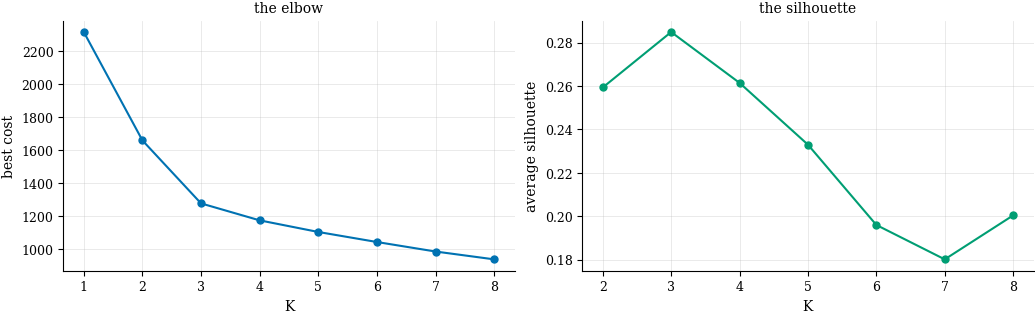

In [4]:
wine = load_wine()
Xs, yw = StandardScaler().fit_transform(wine.data), wine.target
wfits = {K: KMeans(n_clusters=K, n_init=50, random_state=0).fit(Xs) for K in Ks}
wcost = {K: wfits[K].inertia_ for K in Ks}
wsil = {K: silhouette_score(Xs, wfits[K].labels_) for K in Ks if K > 1}
print("drops in the cost:", ", ".join(f"{wcost[K] - wcost[K + 1]:.0f}" for K in (1, 2, 3, 4)))
print("average silhouette:", ", ".join(f"K = {K}: {wsil[K]:.2f}" for K in (2, 3, 4)))
ten = {round(KMeans(4, n_init=10, random_state=s).fit(Xs).inertia_, 2) for s in range(20)}
print(f"K = 4 with 10 starts, 20 seeds: {len(ten)} different final costs")

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.2))
axes[0].plot(list(Ks), [wcost[K] for K in Ks], "o-", color=C0)
axes[0].set_xlabel("K"); axes[0].set_ylabel("best cost"); axes[0].set_title("the elbow", fontsize=10)
axes[1].plot(list(wsil), list(wsil.values()), "o-", color=CG)
axes[1].set_xlabel("K"); axes[1].set_ylabel("average silhouette"); axes[1].set_title("the silhouette", fontsize=10)
plt.show()

The elbow: big drops until $K = 3$ (655 and 381), then 103 and 70, a gentle bend at 3. The silhouette is
highest at $K = 3$ (0.28; 0.26 at $K = 2$ and at $K = 4$). And there are three grape varieties. Nice, but
nothing guarantees it. (With only 10 starts, $K = 4$ stopped at 14 different costs over 20 seeds: that is why
we ask for 50 here.)

## 4. Clustering always answers

500 random points spread evenly over a square: there are **no** groups. k-means still returns the $K$ groups
you ask for. What does the silhouette say? And is this draw special? The cell repeats it on 10 fresh draws of
500 random points.

average silhouette, K = 2..8: 0.36, 0.38, 0.41, 0.39, 0.39, 0.39, 0.39
this draw: the silhouette 'picks' K = 4 with 0.41 (the wine's real groups: 0.28)
10 fresh draws: the best silhouette is between 0.39 and 0.42; the 'best' K is [3, 4, 4, 4, 4, 4, 4, 4, 4, 8]


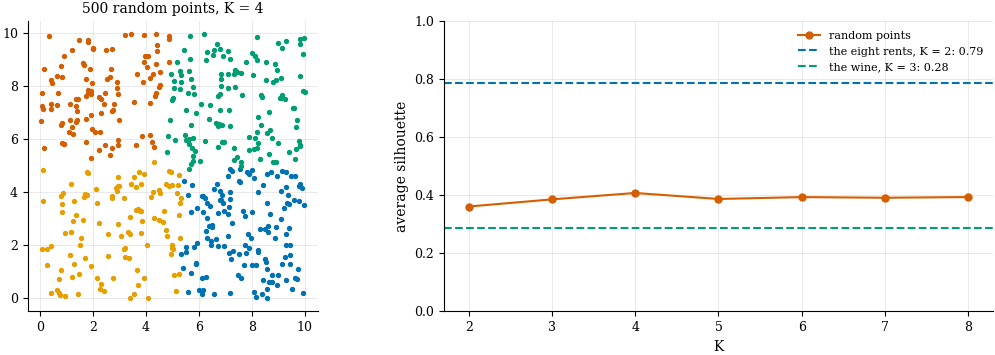

In [5]:
U = make_random_points()
sil_U = {K: silhouette_score(U, KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(U))
         for K in range(2, 9)}
best_K = max(sil_U, key=sil_U.get)
print("average silhouette, K = 2..8:", ", ".join(f"{s:.2f}" for s in sil_U.values()))
print(f"this draw: the silhouette 'picks' K = {best_K} with {sil_U[best_K]:.2f} "
      f"(the wine's real groups: {wsil[3]:.2f})")

N_DRAWS = 10                                           # <-- CHANGE ME: how many fresh draws
picks = []
for seed in range(1, N_DRAWS + 1):
    V = make_random_points(n=len(U), seed=seed)
    sv = {K: silhouette_score(V, KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(V))
          for K in range(2, 9)}
    picks.append((max(sv, key=sv.get), max(sv.values())))
print(f"{N_DRAWS} fresh draws: the best silhouette is between {min(p[1] for p in picks):.2f} and "
      f"{max(p[1] for p in picks):.2f}; the 'best' K is {sorted(p[0] for p in picks)}")

lab4 = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(U)
fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
for k in range(4):
    axes[0].scatter(*U[lab4 == k].T, s=8, color=COLORS[k])
axes[0].set_aspect("equal"); axes[0].set_title(f"{len(U)} random points, K = 4", fontsize=10)
axes[1].plot(list(sil_U), list(sil_U.values()), "o-", color=C1, label="random points")
axes[1].axhline(means[2], color=C0, ls="--", label=f"the eight rents, K = 2: {means[2]:.2f}")
axes[1].axhline(wsil[3], color=CG, ls="--", label=f"the wine, K = 3: {wsil[3]:.2f}")
axes[1].set_ylim(0, 1); axes[1].set_xlabel("K"); axes[1].set_ylabel("average silhouette")
axes[1].legend(fontsize=8, loc="upper right")
plt.show()

The silhouette "picks" $K = 4$ on random points with 0.41, **higher** than the wine's real groups (0.28). Over 10
fresh draws the best silhouette stays between 0.39 and 0.42, always above the wine's 0.28, while the "best"
$K$ wanders (4 on 8 of the 10 draws, 3 and 8 on the others). Its size cannot tell real groups from none. Neither
k-means nor the silhouette ever says "there are no groups here": always check that the groups mean something
for what you need.

**Check yourself.** Your manager wants "the true number of customer types". The silhouette says 4 (0.41). What
do you answer? Which numbers of this section back your answer?

### The first half in one picture

* k-means repeats **join** and **move**; the cost never goes up, and it always stops.
* A random start can get stuck: **restart** (`n_init=10`). The biggest numbers rule the distance:
  **standardize** features in different units. $K$ is **your decision**; the elbow and the silhouette are hints.
* **Use k-means when** the groups are round and of similar size, in comparable units: it is fast, on any amount
  of data.

Next: groups that are **not** round blobs. Here, stretched or unequal groups (**clouds**); in the next
notebook, curved groups (**crowds**) and groups inside groups (**trees**).

## 5. Hard or soft?

Back to the three overlapping blobs. k-means must give every point exactly one group, even a point that sits
between two of them. A **Gaussian mixture** gives each point a **probability** for each group instead, for
instance 70% green and 30% orange, like a forecast of "70% rain" instead of just "rain". The cell fits both and
counts the points that are less than 90% sure of their group.

87 of 420 points are less than 90% sure of their group
the first three points' probabilities:
 [[0.   1.   0.  ]
 [0.72 0.01 0.27]
 [0.97 0.03 0.  ]]


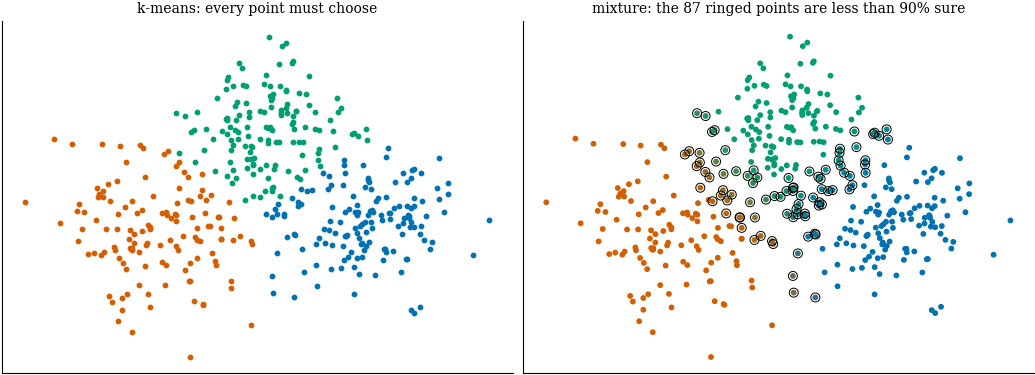

In [6]:
X3, y3 = make_three_blobs()
km3 = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X3)
gm3 = GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=0).fit(X3)
P = gm3.predict_proba(X3)                              # one row per point: its three probabilities
SURE = 0.9                                             # <-- CHANGE ME: how sure counts as sure
unsure = P.max(axis=1) < SURE
print(f"{unsure.sum()} of {len(X3)} points are less than {SURE:.0%} sure of their group")
print("the first three points' probabilities:\n", np.round(P[:3], 2))

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.8))
for k in range(3):
    axes[0].scatter(*X3[km3 == k].T, s=10, color=COLORS[k])
axes[0].set_title("k-means: every point must choose", fontsize=10)
order = [np.bincount(km3[P.argmax(axis=1) == k], minlength=3).argmax() for k in range(3)]  # match k-means' colors
axes[1].scatter(*X3.T, s=10, c=np.clip(P @ RGB[order], 0, 1))     # mixed colors = shared points
axes[1].scatter(*X3[unsure].T, s=42, facecolor="none", edgecolor="k", lw=0.7)   # ring the unsure points
axes[1].set_title(f"mixture: the {unsure.sum()} ringed points are less than {SURE:.0%} sure", fontsize=10)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

87 of the 420 points are less than 90% sure of their group: the ringed points, in the bands between the blobs
(their colors mix the colors of the groups they share). k-means paints the same points with one color and no
warning.

## 6. Each group as a cloud

A **cloud** (a Gaussian) is a center, a **spread** in each direction, a **tilt**, and a **size**: its share of
the points. The story behind a mixture: pick a cloud (bigger ones more often), then drop a point near its
center. A mixture tries to recover the clouds from the points. Three made-up clouds, one round, one stretched
and one stretched and tilted, 120 points each. The cell fits a mixture, prints what it found, and then tells
the story backwards: it draws new points from the fitted clouds.

cloud at (-0.15,  0.10): share 0.34, spreads 0.97 and 0.83 (ratio 1.2), tilt  56 degrees
cloud at ( 3.11,  6.29): share 0.33, spreads 1.88 and 0.47 (ratio 4.0), tilt  50 degrees
cloud at ( 5.86,  0.33): share 0.33, spreads 1.97 and 0.55 (ratio 3.5), tilt  -2 degrees


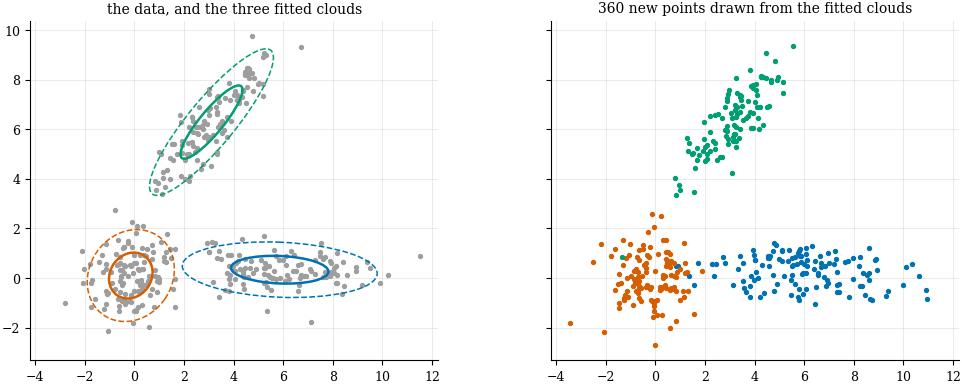

In [7]:
rng = np.random.default_rng(0)
SPECS = [((0.0, 0.0), (0.9, 0.9), 0.0, 120),           # center, spread along and across, tilt (degrees), points
         ((6.0, 0.3), (2.0, 0.55), 0.0, 120),
         ((3.0, 6.2), (2.0, 0.5), 50.0, 120)]
parts = []
for center, spread, tilt, n in SPECS:
    t = np.deg2rad(tilt)
    turn = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    parts.append(rng.normal(size=(n, 2)) * spread @ turn.T + center)
Xc = np.vstack(parts)

gm = GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=0).fit(Xc)
for k in np.argsort(gm.means_[:, 0]):
    vals, vecs = np.linalg.eigh(gm.covariances_[k])
    long, short = np.sqrt(vals[::-1])
    tilt = (np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1])) + 90) % 180 - 90     # between -90 and 90
    print(f"cloud at ({gm.means_[k, 0]:5.2f}, {gm.means_[k, 1]:5.2f}): share {gm.weights_[k]:.2f}, spreads "
          f"{long:.2f} and {short:.2f} (ratio {long / short:.1f}), tilt {tilt:3.0f} degrees")

story = np.random.default_rng(1)                       # the story: pick a cloud, then drop a point near it
which = story.choice(3, size=len(Xc), p=gm.weights_)
new = np.array([story.multivariate_normal(gm.means_[k], gm.covariances_[k]) for k in which])

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.9), sharex=True, sharey=True)
axes[0].scatter(*Xc.T, s=8, color=CX)
for k in range(3):
    draw_cloud(axes[0], gm.means_[k], gm.covariances_[k], COLORS[k])
axes[0].set_title("the data, and the three fitted clouds", fontsize=10)
for k in range(3):
    axes[1].scatter(*new[which == k].T, s=8, color=COLORS[k])
axes[1].set_title(f"{len(new)} new points drawn from the fitted clouds", fontsize=10)
for ax in axes:
    ax.set_aspect("equal")
plt.show()

The mixture recovers the three clouds: one round (its two spreads in a ratio of 1.2; its tilt of 56 degrees
means nothing: the cloud was drawn round, and which way it came out a little longer is chance), one stretched
(ratio 3.5, tilt $-2$ degrees: almost none) and one stretched and tilted (ratio 4.0, tilt 50 degrees), each with
a share of about a third. Points drawn from the fitted clouds look like the data. **k-means' groups are clouds
forced to be round, equally wide and of the same size; a mixture lets every cloud have its own width, stretch,
tilt and size.**

## 7. Soft membership, by hand

Two bells (clouds in one dimension) centered on the two rent groups, 3.5 and 11.5, both with the same width.
A new apartment rents for 7. How much does it belong to each group? Compare the heights of the two bells at 7:
its share of the low group is the low bell's height divided by the sum of the two heights.

**Predict first:** a new apartment rents for 7. Low or high, and how sure?

In [8]:
def bell(x, center, var):
    "a bell's height (peak 1; the common factor of two bells of the same width cancels in the share)"
    return np.exp(-(x - center) ** 2 / (2 * var))


VAR = 8.0                                              # <-- CHANGE ME: the bells' width (variance)
h_low, h_high = bell(7, 3.5, VAR), bell(7, 11.5, VAR)
print(f"variance {VAR:g}: heights at 7 are {h_low:.3g} (low) and {h_high:.3g} (high) -> "
      f"P(low) = {h_low / (h_low + h_high):.2f}")
print(f"\n{'P(low) at rent':>16s}" + "".join(f"{x:>7g}" for x in (6, 7, 7.5, 8)))
for var in sorted({8.0, 1.25, VAR}, reverse=True):     # the two widths of the text, and yours
    shares = [bell(x, 3.5, var) / (bell(x, 3.5, var) + bell(x, 11.5, var)) for x in (6, 7, 7.5, 8)]
    print(f"{f'variance {var:g}':>16s}" + "".join(f"{s:7.2f}" for s in shares))
ratio = bell(7, 3.5, 1.25) / bell(7, 11.5, 1.25)
print(f"variance 1.25: at 7 the low bell is {ratio:.1f} times taller -> {ratio:.1f} / {ratio + 1:.1f} = "
      f"{ratio / (ratio + 1):.2f}")

variance 8: heights at 7 are 0.465 (low) and 0.282 (high) -> P(low) = 0.62

  P(low) at rent      6      7    7.5      8
      variance 8   0.82   0.62   0.50   0.38
   variance 1.25   1.00   0.96   0.50   0.04
variance 1.25: at 7 the low bell is 24.5 times taller -> 24.5 / 25.5 = 0.96


k-means says only "low" (7 is left of the border 7.5). With wide bells (variance 8) the heights at 7 are 0.465
and 0.282, so the mixture says $0.465/(0.465 + 0.282) = 62\%$ low and 38% high. With narrow bells (variance
1.25) the low bell is about 25 times taller at 7 (24.5), so $25/26 = 96\%$ low. **The wider the clouds, the
softer the answer**; very narrow clouds give k-means' hard answer. At 7.5, halfway, it is always 50/50.

**Check yourself.** (a) Make both bells wider. Is the apartment at 7 more or less surely "low"? Which row of the
table answers it? (b) A mixture says customer A is 51% / 49% "bargain hunter" / "brand lover", and customer B
99% / 1%. Whom do you treat differently, and what did k-means say about each?

## 8. EM: k-means with soft memberships

So far we placed the bells ourselves. EM lets the data place them, with the same two moves as k-means' join and
move, only soft. **E-step:** every point works out how much it belongs to each cloud (its share, as in &sect;7,
but every cloud now has its own width and share, so its full height counts). **M-step:** every cloud moves to
the weighted average of its points and reshapes to fit them (a point that is 70% cloud 1 counts as 0.7 of a
point there). The **fit** (the log-likelihood) says how well the clouds explain the points: take the mixture's
height at every point, take the log, add up. Here it is negative, and higher (closer to 0) is better.

First by hand on the eight rents, from two poor wide bells at 4 and 6; scikit-learn's `GaussianMixture` checks
the answer.

In [9]:
def mixture_heights(x, mu, var, w):
    "every rent's height under each bell, times the bell's share (one row per rent, one column per bell)"
    return w * np.exp(-(x[:, None] - mu) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)


mu, var, w = np.array([4.0, 6.0]), np.array([8.0, 8.0]), np.array([0.5, 0.5])   # a poor start
fits_1d = [np.log(mixture_heights(rents, mu, var, w).sum(axis=1)).sum()]       # the fit at the start
print(f"{'start:':12s} centers {mu[0]:5.2f} and {mu[1]:5.2f}, variances {var[0]:5.2f} and {var[1]:5.2f}, "
      f"shares {w[0]:.2f}/{w[1]:.2f}, fit {fits_1d[0]:7.3f}")
for rnd in range(1, 21):
    heights = mixture_heights(rents, mu, var, w)
    share = heights / heights.sum(axis=1, keepdims=True)                            # E-step: one row per rent
    mu = (share * rents[:, None]).sum(axis=0) / share.sum(axis=0)                   # M-step: move,
    var = (share * (rents[:, None] - mu) ** 2).sum(axis=0) / share.sum(axis=0)      # reshape,
    w = share.mean(axis=0)                                                          # and resize
    fits_1d.append(np.log(mixture_heights(rents, mu, var, w).sum(axis=1)).sum())   # the fit after this round
    if rnd in (1, 2, 3, 5, 10, 20):
        print(f"EM round {rnd:2d}: centers {mu[0]:5.2f} and {mu[1]:5.2f}, variances {var[0]:5.2f} and "
              f"{var[1]:5.2f}, shares {w[0]:.2f}/{w[1]:.2f}, fit {fits_1d[-1]:7.3f}")
print(f"the fit never went down: {bool(np.all(np.diff(fits_1d) >= -1e-9))}")

gr = GaussianMixture(n_components=2, covariance_type="spherical", n_init=10, random_state=0).fit(R)
o = np.argsort(gr.means_.ravel())
print(f"\nscikit-learn's mixture: centers {gr.means_.ravel()[o][0]:g} and {gr.means_.ravel()[o][1]:g}, "
      f"variances {gr.covariances_[o][0]:g} and {gr.covariances_[o][1]:g}; "
      f"P(low | rent 7) = {gr.predict_proba([[7.0]])[0, o][0]:.2f}")

start:       centers  4.00 and  6.00, variances  8.00 and  8.00, shares 0.50/0.50, fit -26.594
EM round  1: centers  5.12 and  8.96, variances 11.90 and 14.92, shares 0.38/0.62, fit -22.645
EM round  2: centers  4.80 and  9.15, variances 10.14 and 14.44, shares 0.38/0.62, fit -22.549
EM round  3: centers  4.36 and  9.42, variances  7.61 and 13.41, shares 0.38/0.62, fit -22.273
EM round  5: centers  3.42 and 10.41, variances  1.36 and  8.24, shares 0.42/0.58, fit -19.976
EM round 10: centers  3.50 and 11.50, variances  1.25 and  1.25, shares 0.50/0.50, fit -17.789
EM round 20: centers  3.50 and 11.50, variances  1.25 and  1.25, shares 0.50/0.50, fit -17.789
the fit never went down: True

scikit-learn's mixture: centers 3.5 and 11.5, variances 1.25 and 1.25; P(low | rent 7) = 0.96


EM moves the bells to the data: by round 10 they sit at 3.5 and 11.5 with variance 1.25 (the variance of 2, 3,
4, 5 around 3.5), exactly the narrow bells of &sect;7, and scikit-learn's mixture finds the same, with the same
96% for the rent at 7. The fit never went down: from $-26.594$ at the start to $-17.789$.

Now the three blobs, with three clouds that all start in the middle. scikit-learn runs the rounds (`max_iter` =
the number of rounds), and the cell prints the fit after each round. (On its own, scikit-learn stops once a
round gains less than 0.001 per point: that is the mixture &sect;5 used.)

log-likelihood at the start: -2203.0
log-likelihood after rounds 1-5: -1687.9, -1669.6, -1657.7, -1653.0, -1651.9
rounds 6 to 15 add only 1.23 more; it never went down: True
scikit-learn's own stopping rule: a gain below 0.001 per point


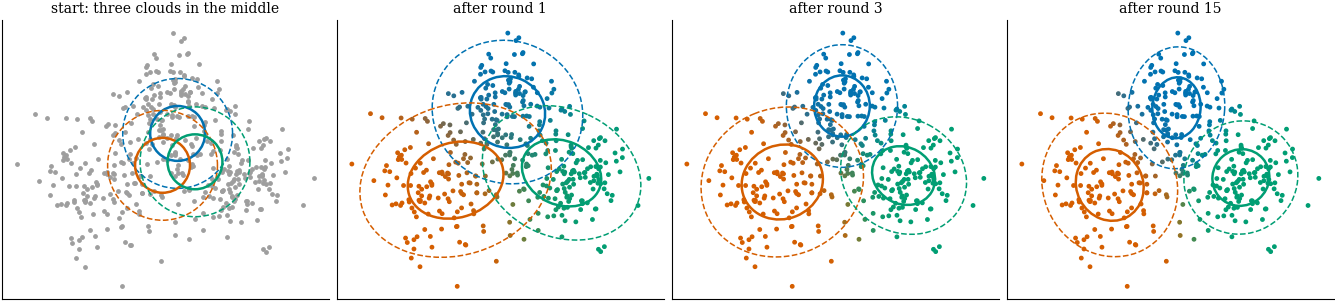

In [10]:
rng = np.random.default_rng(0)
start = X3[rng.choice(len(X3), 3, replace=False)] * 0.3 + X3.mean(axis=0) * 0.7   # three clouds near the middle


def em_rounds(r):
    '''EM from that start, stopped after exactly r rounds. The start: the centers above, equal shares
    (weights_init) and round clouds of spread 1 (precisions_init: one over each cloud's variance, here the
    identity). tol=0 switches off scikit-learn's own stopping rule and reg_covar=0 adds nothing to the
    spreads, so these are the plain E- and M-steps.'''
    g = GaussianMixture(n_components=3, covariance_type="full", means_init=start, weights_init=[1 / 3] * 3,
                        precisions_init=[np.eye(2)] * 3, reg_covar=0.0, tol=0.0, max_iter=r)
    with warnings.catch_warnings():                    # stopping after r rounds on purpose is fine
        warnings.simplefilter("ignore", ConvergenceWarning)
        return g.fit(X3)


d2 = ((X3[:, None, :] - start[None]) ** 2).sum(axis=2)            # the start: round clouds of spread 1
start_fit = np.log((np.exp(-d2 / 2) / (2 * np.pi)).mean(axis=1)).sum()   # each cloud: height e^(-d2/2) / (2 pi), share 1/3
fit = [em_rounds(r).score(X3) * len(X3) for r in range(1, 16)]     # score() is the fit per point; times 420 = the total
print(f"log-likelihood at the start: {start_fit:.1f}")
print("log-likelihood after rounds 1-5:", ", ".join(f"{f:.1f}" for f in fit[:5]))
print(f"rounds 6 to 15 add only {fit[-1] - fit[4]:.2f} more; it never went down: "
      f"{bool(np.all(np.diff(fit) >= -1e-9))}")
print(f"scikit-learn's own stopping rule: a gain below {GaussianMixture().tol} per point")

fig, axes = plt.subplots(1, 4, figsize=(13.4, 3.4), sharex=True, sharey=True)
axes[0].scatter(*X3.T, s=6, color=CX)
for k in range(3):
    draw_cloud(axes[0], start[k], np.eye(2), COLORS[k])
axes[0].set_title("start: three clouds in the middle", fontsize=10)
for ax, r in zip(axes[1:], (1, 3, 15)):
    g = em_rounds(r)
    ax.scatter(*X3.T, s=6, c=np.clip(g.predict_proba(X3) @ RGB[:3], 0, 1))
    for k in range(3):
        draw_cloud(ax, g.means_[k], g.covariances_[k], COLORS[k])
    ax.set_title(f"after round {r}", fontsize=10)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
plt.show()

The first round does most of the work: the log-likelihood jumps from $-2203.0$ at the start to $-1687.9$.
Every round fits at least as well as the last, and the clouds settle: rounds 6 to 15 add only 1.23 more. Mixed
colors are the shared points. Like k-means, EM can stop at a poor answer from a poor start: restart it
(`n_init`).

## 9. Where the shape freedom pays

Two situations where k-means failed: three **tilted clouds**, and a **small group beside a big one**. And the
iris flowers: 150 flowers, 4 measurements each, all lengths in cm (so we keep them as they are), 3 species
hidden. The knob `COV` sets how much freedom the mixture's clouds get: `"full"` (any width, stretch and tilt),
`"diag"` (stretch along the axes only), `"spherical"` (round, each with its own width), `"tied"` (one shape
shared by all). Each comparison is one draw of made-up data, so the cell also repeats the two made-up ones on 10
fresh draws.

tilted clouds    k-means ARI 0.36 (156 misplaced), mixture (full) ARI 0.81 (39 misplaced); group sizes k-means [130, 146, 324], mixture [187, 192, 221]


small beside big k-means ARI 0.21 (52 misplaced), mixture (full) ARI 1.00 (0 misplaced); group sizes k-means [72, 148], mixture [20, 200]


iris             k-means ARI 0.73 (16 misplaced), mixture (full) ARI 0.90 (5 misplaced); group sizes k-means [38, 50, 62], mixture [45, 50, 55]
iris, round clouds (spherical) against k-means: the same grouping? True


10 draws, tilted clouds   : k-means 0.30 to 0.40, mixture 0.76 to 0.80; the mixture wins 10 of 10
    the mixture, draw by draw: [0.79, 0.79, 0.76, 0.79, 0.8, 0.76, 0.8, 0.8, 0.76, 0.8]
10 draws, small beside big: k-means 0.08 to 0.41, mixture 0.55 to 1.00; the mixture wins 10 of 10
    the mixture, draw by draw: [1.0, 0.97, 0.97, 1.0, 0.93, 0.97, 1.0, 0.97, 0.94, 0.55]


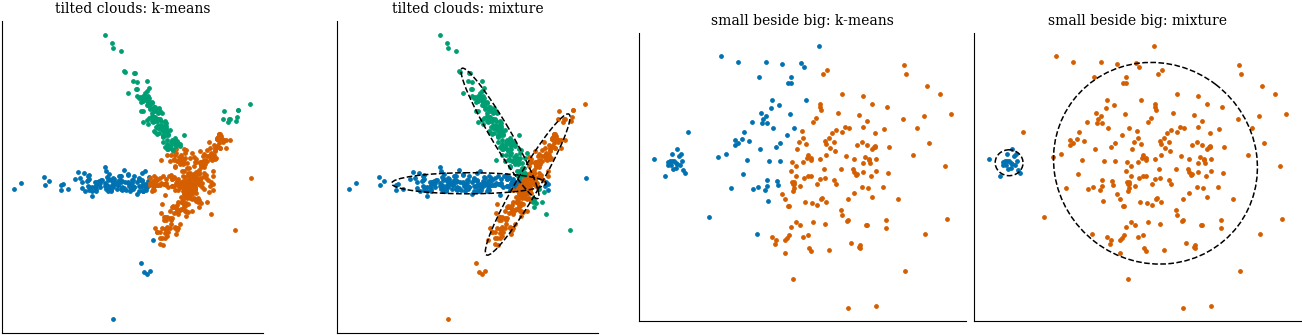

In [11]:
COV = "full"                                           # <-- CHANGE ME: "full", "diag", "spherical" or "tied"
shapes = make_shapes()
iris = load_iris()
cases = {"tilted clouds": shapes["tilted clouds"], "small beside big": shapes["small beside big"],
         "iris": (iris.data, iris.target)}
fitted = {}
for name, (X, y) in cases.items():
    K = len(np.unique(y))
    km = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(X)
    g = GaussianMixture(n_components=K, covariance_type=COV, n_init=10, random_state=0).fit(X)
    gm_lab = g.predict(X)
    fitted[name] = (X, best_renaming(y, km, relabel=True), best_renaming(y, gm_lab, relabel=True), g)
    print(f"{name:16s} k-means ARI {adjusted_rand_score(y, km):.2f} ({len(y) - best_renaming(y, km)} misplaced), "
          f"mixture ({COV}) ARI {adjusted_rand_score(y, gm_lab):.2f} ({len(y) - best_renaming(y, gm_lab)} misplaced); "
          f"group sizes k-means {sorted(np.bincount(km).tolist())}, mixture {sorted(np.bincount(gm_lab).tolist())}")
sph = GaussianMixture(n_components=3, covariance_type="spherical", n_init=10, random_state=0).fit_predict(iris.data)
print(f"iris, round clouds (spherical) against k-means: the same grouping? "
      f"{adjusted_rand_score(fitted['iris'][1], sph) == 1.0}")

rows = {"tilted clouds": [], "small beside big": []}
for seed in range(1, 11):                              # 10 fresh draws of the two made-up situations
    for name, (X, y) in (("tilted clouds", make_ellipses3(seed=seed)),
                         ("small beside big", make_blobs(n_samples=[20, 200], centers=[[0, 0], [6, 0]],
                                                         cluster_std=[0.25, 2.0], random_state=seed))):
        km = KMeans(n_clusters=len(np.unique(y)), n_init=10, random_state=0).fit_predict(X)
        gl = GaussianMixture(n_components=len(np.unique(y)), covariance_type=COV, n_init=10,
                             random_state=0).fit_predict(X)
        rows[name].append((adjusted_rand_score(y, km), adjusted_rand_score(y, gl)))
for name, r in rows.items():
    r = np.array(r)
    print(f"10 draws, {name:16s}: k-means {r[:, 0].min():.2f} to {r[:, 0].max():.2f}, mixture "
          f"{r[:, 1].min():.2f} to {r[:, 1].max():.2f}; the mixture wins {np.sum(r[:, 1] > r[:, 0])} of 10")
    print(f"    the mixture, draw by draw: {np.round(r[:, 1], 2).tolist()}")

fig, axes = plt.subplots(1, 4, figsize=(13.4, 3.4))
for i, name in enumerate(("tilted clouds", "small beside big")):
    X, km, gm_lab, g = fitted[name]
    for k in range(len(np.unique(km))):
        axes[2 * i].scatter(*X[km == k].T, s=6, color=COLORS[k])
        axes[2 * i + 1].scatter(*X[gm_lab == k].T, s=6, color=COLORS[k])
    if COV == "full":
        for k in range(len(g.means_)):
            draw_cloud(axes[2 * i + 1], g.means_[k], g.covariances_[k], "k", sds=(2,))
    axes[2 * i].set_title(f"{name}: k-means", fontsize=10)
    axes[2 * i + 1].set_title(f"{name}: mixture", fontsize=10)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
plt.show()

**Tilted clouds:** k-means 0.36; a mixture fits each cloud's stretch and tilt: 0.81 (where the clouds cross,
nobody can tell). **Small beside big:** k-means splits the big group (72 and 148 points); the mixture finds 20
and 200 exactly: 1.00. **Iris:** k-means misplaces 16 flowers (0.73), the mixture only 5 (0.90), and a mixture
whose clouds must stay round returns exactly k-means' grouping. On 10 fresh draws the mixture still wins all 10
draws of both situations (tilted clouds: k-means 0.30 to 0.40, the mixture 0.76 to 0.80; small beside big: 0.08
to 0.41 against 0.55 to 1.00), but not always cleanly: on one draw of small beside big the mixture scores only
0.55. Like k-means, EM can stop at a poorer answer.

**Each cloud's own tilt fixes the tilted groups; each cloud's own width, with its own share, fixes
small-beside-big. What pays is the shape freedom, not the softness.**

## Recap & exercises

**Recap.**

* **The elbow.** More groups always lower the cost (138, 10, 6, 2, ..., 0), so look for the bend: $K = 2$ on
  the rents, a gentle bend at 3 on the wine.
* **The silhouette** compares a point's distance to its own group ($a$) with its distance to the nearest
  other group ($b$): rent 5 scored 0.69; $K = 2$ won on the rents (0.79) and $K = 3$ on the wine (0.28).
* **Clustering always answers**: random points scored 0.41, more than the wine. $K$ is a decision; the hints
  are hints.
* **A mixture** describes each group as a cloud (center, spread, tilt, size) and gives each point a
  probability for each group: 87 of 420 blob points were less than 90% sure.
* **EM** is k-means made soft: share the points (E-step), then move and reshape the clouds (M-step). The fit
  never gets worse; restart it like k-means.
* **Use a Gaussian mixture when** the groups are stretched, tilted or of unequal size, or when you need "how
  sure".

**Exercises.**

1. In &sect;7, set `VAR` to 1.25, 2 and 30. How sure is the mixture that the rent at 7 is low? Your width joins
   the table: why does 7.5 stay at 0.50 whatever the width?
2. In &sect;5, set `SURE = 0.6`. How many points are now "unsure"? Where are they?
3. In &sect;9, set `COV` to `"diag"`, `"spherical"` and `"tied"` in turn. Which settings still fix the tilted
   clouds, and which still fix small beside big? Match each to the freedoms it keeps: its own tilt, its own
   width, its own share.
4. In &sect;4, use 2,000 random points (`U = make_random_points(n=2000)`; the fresh draws follow). Does the
   silhouette still "pick" a $K$?
5. In &sect;1, the elbow came from k-means. On a line, every group is a run of neighboring rents, so you can try
   every way to cut the sorted rents into $K$ runs: 1, 7, 21, 35, 35, 21, 7, 1 ways for $K = 1..8$. Write that
   loop and check the best costs.
6. **Write it yourself.** Write `silhouette_by_hand(X, labels)` for points in 2-D: the same $a$ and $b$ as in
   &sect;2, with the straight-line distance `np.sqrt(((X - X[i]) ** 2).sum(axis=1))` in place of the 1-D
   `np.abs(... - r)`. Check it on the three blobs of &sect;5 (`X3`, `km3`) against `silhouette_samples(X3, km3)`.
   How many blob points get a negative silhouette, and where are they?
7. In &sect;6, give the round cloud 360 points and the others 60 each (the last number of each row of `SPECS`).
   Do the fitted shares follow?